In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

import joblib

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
DATA_PATH = Path(
    r"D:\Customer-Churn-Analysis\data\processed\customer_churn_cleaned.csv"
)

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (7032, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nChurn distribution:")
print(df["Churn"].value_counts())

print("\nChurn percentages:")
print(df["Churn"].value_counts(normalize=True).mul(100).round(2))

Dataset shape: (7032, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Missing values:
0

Duplicate rows: 0

Churn distribution:
Churn
No     5163
Yes    1869
Name: count, dtype: int64

Churn percentages:
Churn
No     73.42
Yes    26.58
Name: proportion, dtype: float64


In [4]:
# Remove the customer ID and target from the input features
X = df.drop(columns=["customerID", "Churn"])

# Target variable
y = df["Churn"].map({"No": 0, "Yes": 1})

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget counts:")
print(y.value_counts())

Feature shape: (7032, 19)
Target shape: (7032,)

Target counts:
Churn
0    5163
1    1869
Name: count, dtype: int64


In [5]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numeric features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numeric features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining churn rate:", round(y_train.mean() * 100, 2), "%")
print("Testing churn rate:", round(y_test.mean() * 100, 2), "%")

Training rows: 5625
Testing rows: 1407

Training churn rate: 26.58 %
Testing churn rate: 26.58 %


In [7]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [8]:
dummy_model = DummyClassifier(strategy="most_frequent")

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train models
dummy_model.fit(X_train, y_train)
logistic_model.fit(X_train, y_train)
random_forest_model.fit(X_train, y_train)

print("All three models trained successfully!")

All three models trained successfully!


In [9]:
def evaluate_model(name, model, X_test, y_test):
    predictions = model.predict(X_test)

    # Use predicted probabilities for ROC-AUC
    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(X_test)[:, 1]
        auc = roc_auc_score(y_test, probabilities)
    else:
        auc = np.nan

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": auc
    }

In [10]:
results = pd.DataFrame([
    evaluate_model("Dummy Classifier", dummy_model, X_test, y_test),
    evaluate_model("Logistic Regression", logistic_model, X_test, y_test),
    evaluate_model("Random Forest", random_forest_model, X_test, y_test)
])

display(
    results.set_index("Model").round(3)
)

,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model,,,,,
Dummy Classifier,0.734,0.000,0.000,0.000,0.500
Logistic Regression,0.726,0.490,0.797,0.607,0.835
Random Forest,0.784,0.622,0.476,0.539,0.812


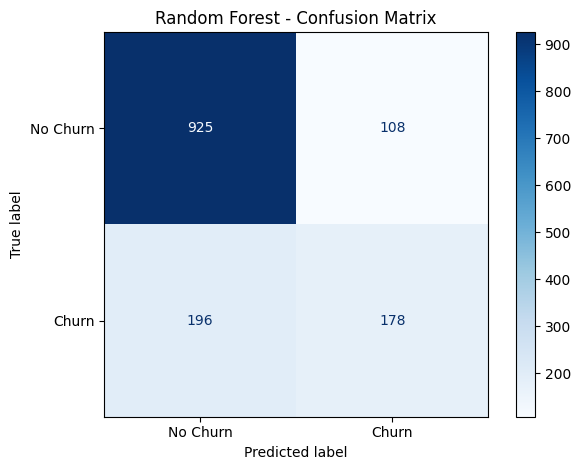

              precision    recall  f1-score   support

    No Churn       0.83      0.90      0.86      1033
       Churn       0.62      0.48      0.54       374

    accuracy                           0.78      1407
   macro avg       0.72      0.69      0.70      1407
weighted avg       0.77      0.78      0.77      1407



In [17]:
rf_predictions = random_forest_model.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_predictions,
    display_labels=["No Churn", "Churn"],
    cmap="Blues"
)

plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
from pathlib import Path

CHART_DIR = Path(
    r"D:\Customer-Churn-Analysis\reports\charts"
)
CHART_DIR.mkdir(parents=True, exist_ok=True)

plt.savefig(
    CHART_DIR / "Random Forest-Confusion Matrix.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print(classification_report(
    y_test,
    rf_predictions,
    target_names=["No Churn", "Churn"],
    zero_division=0
))

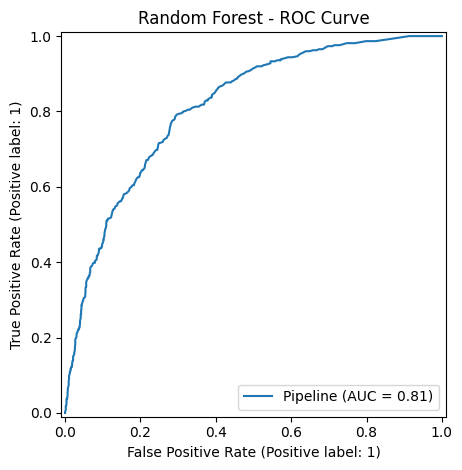

In [18]:
RocCurveDisplay.from_estimator(
    random_forest_model,
    X_test,
    y_test
)

plt.title("Random Forest - ROC Curve")
plt.tight_layout()
from pathlib import Path

CHART_DIR = Path(
    r"D:\Customer-Churn-Analysis\reports\charts"
)
CHART_DIR.mkdir(parents=True, exist_ok=True)

plt.savefig(
    CHART_DIR / "Random Forest - ROC Curve.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


,Feature,Importance
3,num__TotalCharges,0.141739
1,num__tenure,0.129514
2,num__MonthlyCharges,0.123187
36,cat__Contract_Month-to-month,0.075278
38,cat__Contract_Two year,0.037938
18,cat__OnlineSecurity_No,0.037016
27,cat__TechSupport_No,0.030369
43,cat__PaymentMethod_Electronic check,0.029360
16,cat__InternetService_Fiber optic,0.025750
21,cat__OnlineBackup_No,0.017357


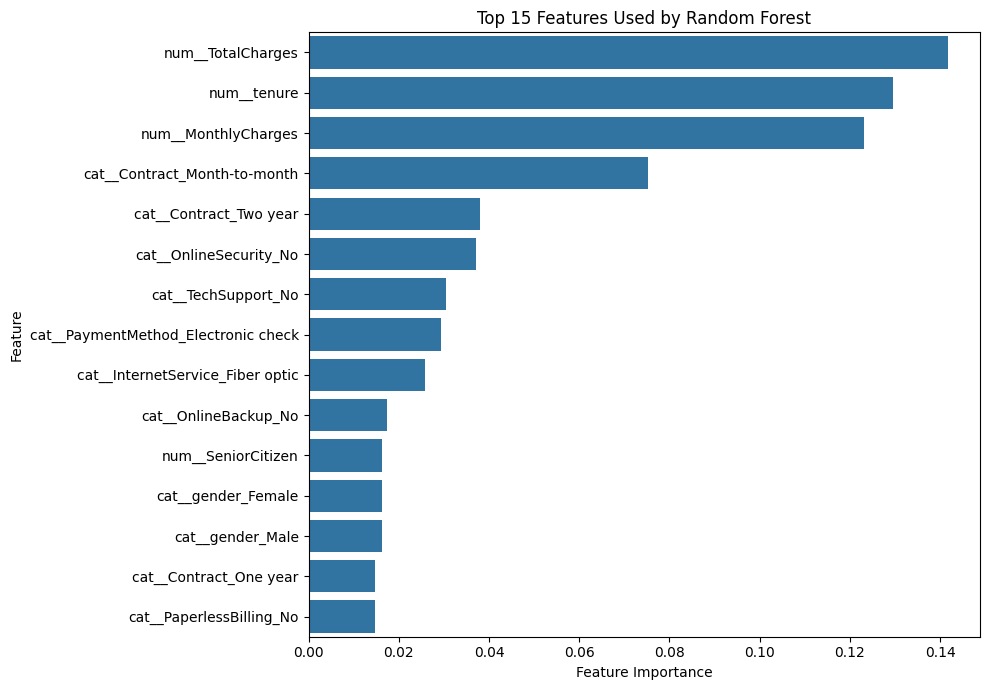

In [19]:
fitted_preprocessor = (
    random_forest_model.named_steps["preprocessor"]
)

feature_names = fitted_preprocessor.get_feature_names_out()

importances = (
    random_forest_model
    .named_steps["classifier"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

display(importance_df.head(15))

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features Used by Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout() 
from pathlib import Path

CHART_DIR = Path(
    r"D:\Customer-Churn-Analysis\reports\charts"
)
CHART_DIR.mkdir(parents=True, exist_ok=True)

plt.savefig(
    CHART_DIR / "Top 15 Features.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


In [20]:
MODEL_DIR = Path(r"D:\Customer-Churn-Analysis\models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    random_forest_model,
    MODEL_DIR / "customer_churn_random_forest.joblib"
)

print("Model saved successfully!")

Model saved successfully!


In [21]:
# Take one customer from the test set
sample_customer = X_test.iloc[[0]]

prediction = random_forest_model.predict(sample_customer)[0]
probability = random_forest_model.predict_proba(sample_customer)[0, 1]

print("Predicted churn:", "Yes" if prediction == 1 else "No")
print(f"Estimated churn probability: {probability:.2%}")

Predicted churn: No
Estimated churn probability: 0.00%


In [22]:
from pathlib import Path

REPORT_DIR = Path(
    r"D:\Customer-Churn-Analysis\reports"
)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

results.to_csv(
    REPORT_DIR / "model_metrics.csv",
    index=False
)

print(results.round(3))
print("\nModel metrics saved successfully.")

                 Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
0     Dummy Classifier     0.734      0.000   0.000     0.000    0.500
1  Logistic Regression     0.726      0.490   0.797     0.607    0.835
2        Random Forest     0.784      0.622   0.476     0.539    0.812

Model metrics saved successfully.
